# Project Deliverable 1: Data Collection, Cleaning, and Exploration
**Course:** MSCS-634-A01 — Advanced Big Data and Data Mining  
**Student:** Corey Hyde  
**Student ID:** 003044072

## Objective
Explore and prepare the UCI Online Retail dataset for future predictive modeling. All results are generated by running the notebook; conclusions should be updated after reviewing the outputs.

## 1. Dataset selection
The [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail) contains 541,909 transactions with eight original fields from a UK-based online retailer (2010–2011). Its transaction, product, time, price, and customer fields support future regression, classification, clustering, and association-rule mining. Engineered variables add further attributes. Download **Online Retail.xlsx** from UCI and place it in `data/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_PATH = Path("data/Online Retail.xlsx")
if not DATA_PATH.exists():
    raise FileNotFoundError("Download Online Retail.xlsx from https://archive.ics.uci.edu/dataset/352/online+retail and save to data/")
df = pd.read_excel(DATA_PATH, engine="openpyxl")
print("Shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all").T)

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality audit
Missing customer identifiers are not fabricated. Duplicate records are removed, and transactions with nonpositive quantity or unit price are excluded from the **sales-only** analytical dataset. Returns and cancellations are kept in a separate dataset for future research. Extremely large purchases are inspected, not automatically deleted.

In [2]:
print("Missing values:\n", df.isna().sum())
print("Exact duplicates:", df.duplicated().sum())
print("Nonpositive quantity:", (df.Quantity <= 0).sum())
print("Nonpositive price:", (df.UnitPrice <= 0).sum())
print("Cancelled invoices:", df.InvoiceNo.astype(str).str.startswith("C").sum())
print("Missing descriptions:", df.Description.isna().sum())

Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Exact duplicates: 5268
Nonpositive quantity: 10624
Nonpositive price: 2517
Cancelled invoices: 9288
Missing descriptions: 1454


In [3]:
clean = df.drop_duplicates().copy()
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce")
clean["Description"] = clean["Description"].astype("string").str.strip()
clean["Country"] = clean["Country"].astype("string").str.strip()
clean["InvoiceNo"] = clean["InvoiceNo"].astype(str).str.strip()
clean["StockCode"] = clean["StockCode"].astype(str).str.strip()
# Retain non-sale records separately to avoid conflating refunds and purchases.
returns = clean[(clean["Quantity"] <= 0) | clean["InvoiceNo"].str.startswith("C")].copy()
sales = clean.loc[(clean.Quantity > 0) & (clean.UnitPrice > 0) & clean.InvoiceDate.notna() & (~clean.InvoiceNo.str.startswith("C")) & clean.Description.notna() & clean.Country.notna()].copy()
sales["TotalPrice"] = sales.Quantity * sales.UnitPrice
sales["Month"] = sales.InvoiceDate.dt.to_period("M").astype(str)
sales["DayOfWeek"] = sales.InvoiceDate.dt.day_name()
sales["Hour"] = sales.InvoiceDate.dt.hour
print("Raw rows:", len(df), "Sales rows:", len(sales), "Returns/cancellations:", len(returns))
print("Sales attributes:", sales.shape[1])
display(sales.head())

Raw rows: 541909 Sales rows: 524878 Returns/cancellations: 10587
Sales attributes: 12


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Month,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8


## 3. Explore distributions and outliers
High-value orders can be legitimate bulk purchases. The analysis uses a 99th-percentile display limit only for visualization, without removing those observations from the underlying dataset.

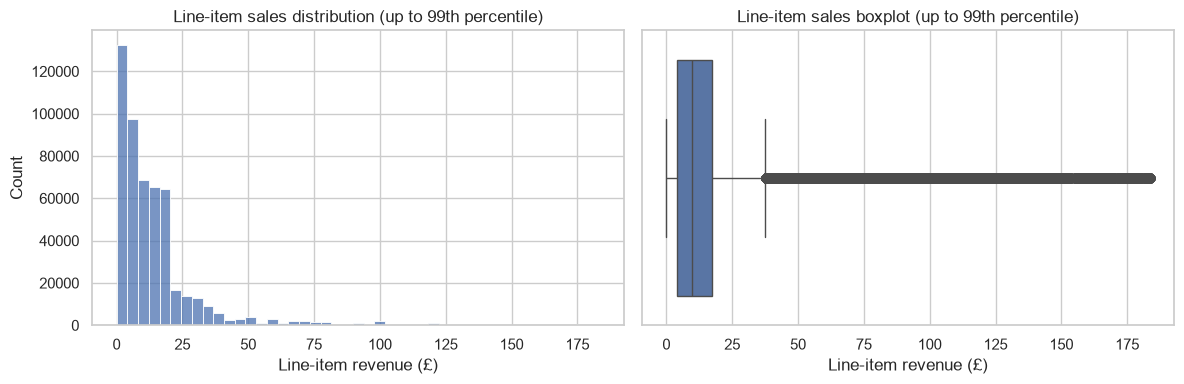

99th percentile: 183.6
Maximum line-item total: 168469.6


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
limit = sales.TotalPrice.quantile(.99)
sns.histplot(sales.loc[sales.TotalPrice <= limit, "TotalPrice"], bins=45, ax=axes[0])
axes[0].set(title="Line-item sales distribution (up to 99th percentile)", xlabel="Line-item revenue (£)")
sns.boxplot(x=sales.loc[sales.TotalPrice <= limit, "TotalPrice"], ax=axes[1])
axes[1].set(title="Line-item sales boxplot (up to 99th percentile)", xlabel="Line-item revenue (£)")
plt.tight_layout(); plt.show()
print("99th percentile:", round(limit, 2))
print("Maximum line-item total:", round(sales.TotalPrice.max(), 2))

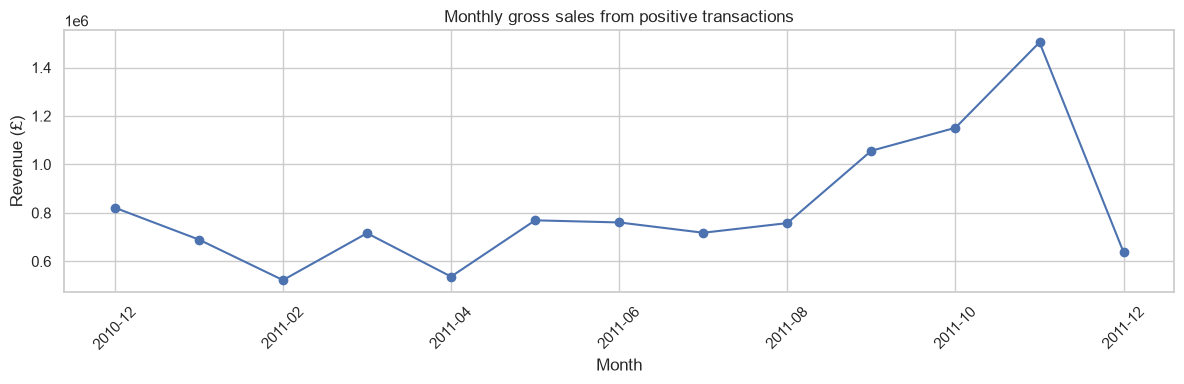

Highest revenue month: 2011-11
Note: December 2011 is a partial month; avoid direct full-month comparisons.


In [5]:
monthly = sales.groupby("Month", sort=True).TotalPrice.sum()
plt.figure(figsize=(12, 4)); monthly.plot(marker="o")
plt.title("Monthly gross sales from positive transactions"); plt.ylabel("Revenue (£)"); plt.xlabel("Month")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print("Highest revenue month:", monthly.idxmax())
print("Note: December 2011 is a partial month; avoid direct full-month comparisons.")

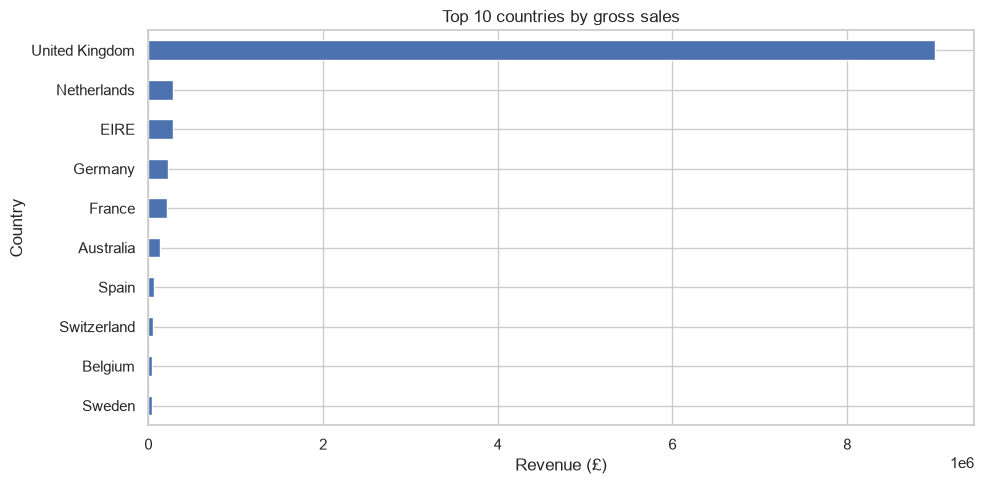

UK share of positive sales revenue: 84.6%


In [6]:
top_countries = sales.groupby("Country").TotalPrice.sum().nlargest(10).sort_values()
plt.figure(figsize=(10, 5)); top_countries.plot(kind="barh")
plt.title("Top 10 countries by gross sales"); plt.xlabel("Revenue (£)"); plt.tight_layout(); plt.show()
print("UK share of positive sales revenue:", f"{sales.loc[sales.Country.eq('United Kingdom'), 'TotalPrice'].sum()/sales.TotalPrice.sum():.1%}")

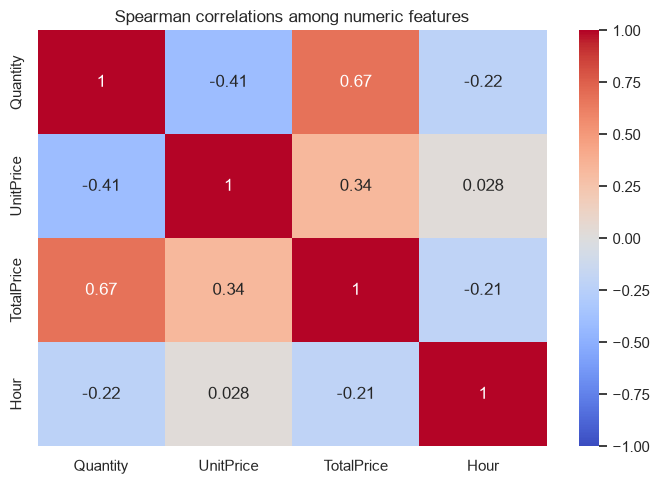

Missing CustomerID in sales: 132186
Distinct invoices: 19960
Distinct products: 3922


In [7]:
numeric = sales[["Quantity", "UnitPrice", "TotalPrice", "Hour"]]
plt.figure(figsize=(7, 5)); sns.heatmap(numeric.corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlations among numeric features"); plt.tight_layout(); plt.show()
print("Missing CustomerID in sales:", sales.CustomerID.isna().sum())
print("Distinct invoices:", sales.InvoiceNo.nunique())
print("Distinct products:", sales.StockCode.nunique())

## 4. Prepare data for future deliverables
The full positive-sales dataset supports revenue regression and transaction basket analysis. For customer-level clustering and classification, records with missing CustomerID should be excluded from the customer-level view rather than assigned fabricated identifiers. Future classification targets must be defined carefully to avoid leakage; future-period purchases could support a repeat-purchase label.

In [8]:
customer_sales = sales.dropna(subset=["CustomerID"]).copy()
customer_features = customer_sales.groupby("CustomerID").agg(
    order_count=("InvoiceNo", "nunique"),
    total_spend=("TotalPrice", "sum"),
    items_purchased=("Quantity", "sum"),
    last_purchase=("InvoiceDate", "max")
).reset_index()
print("Customer-level records:", len(customer_features))
display(customer_features.head())
Path("outputs").mkdir(exist_ok=True)
sales.to_csv("outputs/cleaned_sales.csv", index=False)
returns.to_csv("outputs/returns_and_cancellations.csv", index=False)
customer_features.to_csv("outputs/customer_features.csv", index=False)
print("Saved cleaned datasets in outputs/")

Customer-level records: 4338


,CustomerID,order_count,total_spend,items_purchased,last_purchase
0,12346.0,1,77183.60,74215,2011-01-18 10:01:00
1,12347.0,7,4310.00,2458,2011-12-07 15:52:00
2,12348.0,4,1797.24,2341,2011-09-25 13:13:00
3,12349.0,1,1757.55,631,2011-11-21 09:51:00
4,12350.0,1,334.40,197,2011-02-02 16:01:00


Saved cleaned datasets in outputs/




## References
UCI Machine Learning Repository. (2015). *Online Retail* [Dataset]. https://doi.org/10.24432/C5BW33

Han, J., Pei, J., & Tong, H. (2022). *Data mining* (4th ed.). Elsevier.

Wu, D. (2024). *Data mining with Python*. Taylor & Francis.